In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt

from helpers import load_csv_data, create_csv_submission

%matplotlib inline

DATA_PATH = "dataset"
CACHE_PATH = os.path.join(DATA_PATH, "data.npz")

# Parsing the CSVs is slow, so cache the arrays after the first load
if os.path.exists(CACHE_PATH):
    data = np.load(CACHE_PATH)
    x_train, x_test, y_train, train_ids, test_ids = (
        data[k] for k in ["x_train", "x_test", "y_train", "train_ids", "test_ids"]
    )
else:
    x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)
    np.savez(
        CACHE_PATH,
        x_train=x_train,
        x_test=x_test,
        y_train=y_train,
        train_ids=train_ids,
        test_ids=test_ids,
    )

# Logistic regression expects labels in {0, 1}; the dataset uses {-1, 1}
y_train = (y_train == 1).astype(float)

print("x_train:", x_train.shape, " y_train:", y_train.shape, " x_test:", x_test.shape)
print("positive rate:", y_train.mean())
print("share of missing values in x_train:", np.isnan(x_train).mean())

x_train: (328135, 321)  y_train: (328135,)  x_test: (109379, 321)
positive rate: 0.08830207079403295
share of missing values in x_train: 0.4478798165806975


Samples: 328135, features: 321
Positive rate: 0.088
Columns with any NaN: 239, with >50% NaN: 147
Five-number summary, first 3 columns (min, Q1, median, Q3, max):
[[1.0000000e+00 1.9000000e+01 2.9000000e+01 4.4000000e+01 7.2000000e+01]
 [1.0000000e+00 3.0000000e+00 6.0000000e+00 9.0000000e+00 1.2000000e+01]
 [1.0120160e+06 3.2320150e+06 6.2420150e+06 1.0022015e+07 1.2312015e+07]]
Highest-missing columns: [ 14  11 191 147 148 152 154 153 151 150] [1.    1.    0.999 0.999 0.999 0.999 0.999 0.999 0.999 0.999]


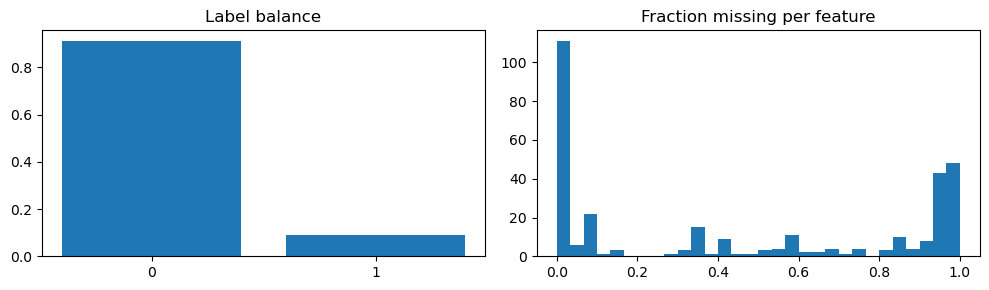

x_train_pp: (328135, 185)  x_test_pp: (109379, 185)
NaNs left: 0 0
Features: original 321 -> kept 184 (incl. 92 candidate missing-flags before pruning)


In [2]:
# ---------- look at the data before changing it ----------
def quick_eda(x, y, top=10):
    """Print basic facts about the data so we can choose sensible thresholds."""
    print(f"Samples: {x.shape[0]}, features: {x.shape[1]}")

    # Fraction of label 1. Far from 0.5 means imbalanced classes,
    # which affects how you should evaluate the model (accuracy can mislead).
    print(f"Positive rate: {y.mean():.3f}")

    # Fraction of NaNs per feature (column). axis=0 means "down the rows".
    miss = np.isnan(x).mean(axis=0)
    print(f"Columns with any NaN: {(miss > 0).sum()}, with >50% NaN: {(miss > 0.5).sum()}")

    # Five-number summary per feature: min, Q1, median, Q3, max.
    # nanpercentile ignores NaNs. Large gaps between Q3 and max hint at outliers.
    q = np.nanpercentile(x, [0, 25, 50, 75, 100], axis=0)
    print("Five-number summary, first 3 columns (min, Q1, median, Q3, max):")
    print(np.round(q[:, :3].T, 3))

    # The `top` features with the most missing data: their indices, then their fractions.
    print("Highest-missing columns:", np.argsort(-miss)[:top], np.round(np.sort(-miss)[:top] * -1, 3))

quick_eda(x_train, y_train)

# Two simple plots: class balance, and how much missing data each feature has.
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].bar(["0", "1"], [(y_train == 0).mean(), (y_train == 1).mean()])
ax[0].set_title("Label balance")
ax[1].hist(np.isnan(x_train).mean(axis=0), bins=30)   # many features near 0, a few near 1?
ax[1].set_title("Fraction missing per feature")
plt.tight_layout(); plt.show()


# ---------- 2. Preprocessor: fit on TRAIN only, apply to anything ----------

def _signed_log1p(a):
    """log(1 + |a|) while keeping the sign. Compresses large values (long tails)
    but still works for negative numbers, unlike a plain log."""
    return np.sign(a) * np.log1p(np.abs(a))


def _stage1(x, p):
    """Cleaning steps that happen BEFORE standardization.
    Uses only the saved parameters in `p`, so it behaves the same on any dataset."""

    # Keep only the columns that were not mostly missing during fit.
    X = x[:, p["keep_cols"]].astype(float)

    # Missing-value indicators: 1.0 where the value was NaN, else 0.0.
    # The fact that a value is missing can itself carry signal. It is like giving
    # an "Unknown" category its own binary feature. Built BEFORE imputing, or the
    # NaNs would be gone.
    ind = np.isnan(X[:, p["ind_cols"]]).astype(float)

    # Median imputation: replace each NaN with that column's training median.
    # The median is robust to outliers, unlike the mean.
    X = np.where(np.isnan(X), p["median"], X)

    # Winsorizing: clip values to the training 1st-99th percentile range, so a few
    # extreme values can't dominate. Gradient-based models like logistic regression
    # are sensitive to this.
    X = np.clip(X, p["lo"], p["hi"])

    # Log-compress only the columns flagged as heavily skewed during fit.
    s = p["skewed"]                      # boolean mask over columns
    X[:, s] = _signed_log1p(X[:, s])

    # Final layout: [cleaned numeric features | missing-value flags]
    return np.hstack([X, ind])


def fit_preprocessor(x, max_missing=0.5, clip_pct=(1, 99), skew_thresh=1.0, corr_thresh=0.95):
    """Learn everything needed from the TRAINING data and store it in a dict `p`.

    max_missing : drop a feature if more than this fraction of it is NaN
    clip_pct    : percentiles used as clipping bounds (outlier control)
    skew_thresh : features with |skewness| above this get a log transform
    corr_thresh : of two features correlated above this, drop the later one (redundant)
    """
    p = {}

    # (a) Drop features that are mostly missing. Imputing 50%+ of a column
    #     mostly invents data, so such a column is more noise than signal.
    miss = np.isnan(x).mean(axis=0)
    p["keep_cols"] = np.where(miss <= max_missing)[0]     # indices of columns we keep
    X = x[:, p["keep_cols"]].astype(float)

    # (b) Remember which of the kept columns have at least one NaN.
    #     Only those get a missing-value indicator (a flag for a column
    #     with no NaNs would be all zeros and useless).
    p["ind_cols"] = np.where(np.isnan(X).any(axis=0))[0]

    # (c) Robust statistics, computed ignoring NaNs:
    #     per-column median (for imputing) and 1st/99th percentiles (clip bounds).
    p["median"] = np.nanmedian(X, axis=0)
    p["lo"], p["hi"] = np.nanpercentile(X, clip_pct, axis=0)

    # (d) Detect skewed columns, measured AFTER imputing and clipping so the
    #     outliers we already handle don't inflate the skewness.
    #     Skewness = mean of ((x - mean)/std)^3. Near 0 is symmetric, large is a long tail.
    Xc = np.clip(np.where(np.isnan(X), p["median"], X), p["lo"], p["hi"])
    std = Xc.std(axis=0)
    safe_std = np.where(std > 0, std, 1)     # avoid dividing by 0 for constant columns
    skew = np.where(std > 0, (((Xc - Xc.mean(axis=0)) / safe_std) ** 3).mean(axis=0), 0)
    p["skewed"] = np.abs(skew) > skew_thresh  # boolean mask: log-transform these

    # (e) Run stage 1 on the training data to get the exact matrix we will
    #     standardize, then record each column's mean and standard deviation.
    #     Standardizing (mean 0, std 1) puts all features on one scale, which makes
    #     gradient descent converge faster and treats features comparably.
    Z = _stage1(x, p)
    p["mean"], p["std"] = Z.mean(axis=0), Z.std(axis=0)

    #     Constant columns (std ~ 0) carry no information and would cause a divide by 0.
    nonconst = np.where(p["std"] > 1e-12)[0]
    Zs = (Z[:, nonconst] - p["mean"][nonconst]) / p["std"][nonconst]

    # (f) Remove redundant features. If two columns are almost perfectly correlated,
    #     the second adds little new information. Greedy rule: walk through the
    #     columns in order and keep one only if it is NOT highly correlated with any
    #     column we already kept.
    corr = np.abs(np.corrcoef(Zs, rowvar=False))   # |correlation| between every pair
    kept = []
    for j in range(Zs.shape[1]):
        if not kept or corr[j, kept].max() < corr_thresh:
            kept.append(j)

    # Map the kept positions back to column indices of the stage-1 matrix.
    p["final_cols"] = nonconst[kept]
    return p


def transform(x, p, add_bias=True):
    """Apply the saved preprocessing to any dataset (train, validation or test)."""
    Z = _stage1(x, p)                                           # clean + reshape
    Z = (Z - p["mean"]) / np.where(p["std"] > 1e-12, p["std"], 1.0)  # standardize
    Z = Z[:, p["final_cols"]]                                   # keep only the selected features

    # Bias column: a column of ones, so the model can learn an intercept term.
    # Set add_bias=False if your model code already adds one.
    return np.hstack([np.ones((Z.shape[0], 1)), Z]) if add_bias else Z


# ---------- 3. Apply ----------
params = fit_preprocessor(x_train)             # learn everything from train only
x_train_pp = transform(x_train, params)        # preprocess the training features
x_test_pp = transform(x_test, params)          # test uses the TRAIN statistics (no leakage)


# ---------- 4. Labels: validate (already {0,1} from your cell) ----------
# The loading cell already did y_train = (y_train == 1). Here we just make sure
# nothing is broken before training.
y_train_pp = np.asarray(y_train, dtype=float)
assert set(np.unique(y_train_pp)) <= {0.0, 1.0}, "labels must be in {0, 1}"
assert not np.isnan(y_train_pp).any(), "labels contain NaN"


# ---------- 5. Sanity checks ----------
print("x_train_pp:", x_train_pp.shape, " x_test_pp:", x_test_pp.shape)
print("NaNs left:", np.isnan(x_train_pp).sum(), np.isnan(x_test_pp).sum())   # both should be 0
print("Features: original", x_train.shape[1], "-> kept", len(params["final_cols"]),
      f"(incl. {len(params['ind_cols'])} candidate missing-flags before pruning)")

In [3]:
# Save the preprocessed data as CSV files
np.savetxt("x_train_preprocessed.csv", x_train_pp, delimiter=",")
np.savetxt("y_train_preprocessed.csv", y_train_pp, delimiter=",")
np.savetxt("x_test_preprocessed.csv", x_test_pp, delimiter=",")